# Tutorial: Numerical Diffusion Solver in Soft Potato

The `softpotato.solver` module is the computational core of the Soft Potato simulator. While the `analytical` module provides closed-form solutions for idealized conditions, the `solver` module numerically integrates partial differential equations (PDEs) for arbitrary spatial grids, multi-species reaction-diffusion mechanisms, and realistic boundary conditions.

---

## 1. Introduction: The Core of the Soft Potato Simulator

At the heart of the Soft Potato simulation capability is its modular numerical solver framework. In electrochemical and chemical systems, mass transport is governed by Fick's laws of diffusion, often coupled with homogeneous chemical reactions and interfacial electron transfer:

$$\frac{\partial c_i}{\partial t} = D_i \nabla^2 c_i + R_i(\mathbf{c}, x, t)$$

### Multi-Solver Architecture

Soft Potato is engineered with internal support for multiple numerical solvers. Depending on your system's stiffness, boundary complexity, and performance requirements, you can switch between solvers seamlessly using `get_solver(name)`:

| Solver Identifier | Numerical Method | Key Properties |
| :--- | :--- | :--- |
| `'explicit'` (or `'ftcs'`) | Explicit Forward-Time Central-Space (FTCS) | Intuitive, simple finite differences; conditionally stable governed by the CFL criterion ($\Delta t \le \Delta x^2 / 2D$). |
| `'implicit'` (or `'btcs'`) | Implicit Backward-Time Central-Space (BTCS) | Implicit tridiagonal matrix solve; unconditionally stable for large time steps. |
| `'crank_nicolson'` | Crank–Nicolson | Second-order accurate in both space and time; unconditionally stable and energy-conserving. |
| `'scipy_ivp'` (or `'solve_ivp'`) | Method of Lines via SciPy | Adaptive high-order integrators (`'Radau'`, `'BDF'`, `'RK45'`); ideal for stiff reaction-diffusion systems. |

> **Tutorial Focus:**
> In this tutorial, the **explicit finite difference solver** (`'explicit'`) will be used. We will simulate a two-species redox system ($O$ and $R$) diffusing across a 1D spatial domain, step through the explicit discretization scheme, and extract both concentration profiles and electrochemical currents.

---

## 2. Minimal Code to Run the Simulation

Below is the complete, self-contained minimal code required to set up the physical parameters and spatial grid, formulate the `DiffusionProblem`, execute the explicit numerical solver, and extract the resulting concentrations and Faradaic currents.

> **What follows next:**
> This minimal code contains all essential building blocks of a Soft Potato simulation. The following sections break down each component step-by-step:
> 1. **Parameters & Physical System** (Section 3)
> 2. **Spatial Grid with `np.linspace()`** (Section 4)
> 3. **Boundary and Initial Conditions** (Section 5)
> 4. **Formulating the `DiffusionProblem`** (Section 6)
> 5. **Solver Execution** (Section 7)
> 6. **Extracting & Plotting Concentrations** (Section 8)
> 7. **Extracting & Plotting Currents** (Section 9)

In [7]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import numpy as np
from softpotato.solver import DiffusionProblem, DirichletBC, get_solver

# 1. Physical parameters & spatial grid
D = 1e-5                          # Standard aqueous diffusion coefficient (cm²/s)
grid = np.linspace(0.0, 0.1, 101) # 1 mm domain with 101 points (cm)

# 2. DiffusionProblem setup
problem = DiffusionProblem(
    grid=grid,
    diffusivity={"O": D, "R": D},
    boundary_conditions={
        "O": (DirichletBC(1.0), DirichletBC(0.0)),
        "R": (DirichletBC(0.0), DirichletBC(1.0)),
    },
    initial_conditions={"O": 0.0, "R": 1.0},
    n_electrons=1,
    electrodes="left",
)

# 3. Solver execution
solver = get_solver("explicit")
result = solver.solve(problem, t_span=(0.0, 1.0), t_eval=np.linspace(0.0, 1.0, 101))

# 4. Extract concentrations and currents
c_O = result["O"]
c_R = result["R"]
current_O = result.currents["O"]
current_R = result.currents["R"]

print(f"Simulation completed: {result.message}")
print(f"Concentration matrix shape [O]: {c_O.shape} (time steps × grid points)")
print(f"Extracted current [O] at t = 1.0 s: {current_O[-1]:.4f} A")
print(f"Extracted current [R] at t = 1.0 s: {current_R[-1]:.4f} A")

Simulation completed: Explicit finite difference solution completed successfully.
Concentration matrix shape [O]: (101, 101) (time steps × grid points)
Extracted current [O] at t = 1.0 s: 175.4821 A
Extracted current [R] at t = 1.0 s: -175.4821 A


---

## 3. Physical Parameters & The Simulated System

The first component in our minimal script specifies the physical parameters:

```python
D = 1e-5  # Standard aqueous diffusion coefficient (cm²/s)
```

In electrochemistry, we frequently study an electron transfer reaction occurring at an electrode surface:

$$O + n e^- \rightleftharpoons R$$

- **Species $O$:** The oxidized chemical species.
- **Species $R$:** The reduced chemical species.
- **Diffusivity ($D$):** For small ions and uncharged molecules in room-temperature aqueous solutions, standard diffusion coefficients typically range between $0.5 \times 10^{-5}$ and $2.0 \times 10^{-5}\text{ cm}^2/\text{s}$. Here we choose the canonical value $D_O = D_R = 1.0 \times 10^{-5}\text{ cm}^2/\text{s}$.
- **Reaction stoichiometry:** $n = 1$ electron transferred per elementary reaction step.

---

## 4. Discretizing Space: Building a Grid with `np.linspace()`

The second component of the minimal script builds the 1D spatial coordinate array:

```python
grid = np.linspace(0.0, 0.1, 101)  # 1 mm domain with 101 spatial points (cm)
```

### Choosing the Domain Length $L$
In planar semi-infinite diffusion, the characteristic diffusion penetration layer thickness after experiment duration $t_{\text{end}}$ is given by:

$$\delta \approx 6 \sqrt{D t_{\text{end}}}$$

For $D = 10^{-5}\text{ cm}^2/\text{s}$ and $t_{\text{end}} = 1.0\text{ s}$:

$$\delta \approx 6 \sqrt{10^{-5} \times 1.0} \approx 0.019\text{ cm} \quad (190\ \mu\text{m})$$

To ensure that the right boundary behaves as an undisturbed semi-infinite bulk reservoir throughout the entire duration of the experiment, domain length $L$ must be chosen comfortably larger than $\delta$ (typically $L \ge 5\delta$). Setting $L = 0.1\text{ cm}$ ($1\text{ mm}$) provides a safety factor of $> 5\times$.

### Spatial Discretization and the CFL Stability Condition
With $N_x = 101$ uniformly spaced points, the spatial grid step size is:

$$\Delta x = \frac{L}{N_x - 1} = \frac{0.1}{100} = 10^{-3}\text{ cm} = 10\ \mu\text{m}$$

Because the explicit Forward-Time Central-Space (FTCS) finite difference scheme is conditionally stable, the numerical time step $\Delta t$ must obey the **Courant–Friedrichs–Lewy (CFL) stability criterion**:

$$\Delta t \le \frac{\Delta x^2}{2 D_{\max}} = \frac{(10^{-3})^2}{2 \times 10^{-5}} = 0.05\text{ s}$$

If a custom `dt` is not explicitly provided, Soft Potato automatically chooses a conservative time step ($0.45 \times \text{CFL limit} = 0.0225\text{ s}$) to guarantee unconditionally stable calculations.

In [8]:
# Inspect grid properties
L = 0.1
nx = 101
grid = np.linspace(0.0, L, nx)
dx = grid[1] - grid[0]
cfl_dt_limit = (dx ** 2) / (2.0 * D)

print(f"Domain length (L):             {L:.4f} cm ({L * 1e4:.0f} µm)")
print(f"Spatial interval (dx):         {dx * 1e4:.1f} µm ({dx:.6f} cm)")
print(f"Theoretical CFL limit (dt):    {cfl_dt_limit:.4f} s")

Domain length (L):             0.1000 cm (1000 µm)
Spatial interval (dx):         10.0 µm (0.001000 cm)
Theoretical CFL limit (dt):    0.0500 s


---

## 5. Boundary and Initial Conditions: Dirichlet vs. Neumann

To solve the diffusion equation, we must state what concentrations exist initially throughout the domain, and what happens at the two domain boundaries: the **electrode surface** ($x = 0$, left boundary) and the **bulk solution** ($x = L$, right boundary).

### Understanding Boundary Conditions in Lay Terms
The two universal types of boundary conditions used in physical modeling and electrochemistry are **Dirichlet** and **Neumann** conditions:

#### 1. Dirichlet Boundary Conditions ("Fixed Concentration")
- **In lay terms:** You specify and lock the **exact value** of the concentration at the boundary point. Regardless of what is occurring inside the bulk solution, the boundary point is forced to maintain that fixed concentration at all times.
- **Everyday analogy:** Setting your room air conditioner thermostat to exactly $21^\circ\text{C}$. The wall temperature is locked at $21^\circ\text{C}$, and heat flows into or out of the room to adjust to that clamped value.
- **Electrochemical meaning:** An electrode held under strong potentiostatic control (clamped voltage). If we apply a sufficiently negative potential, every reactant molecule $O$ that reaches the electrode surface is instantly reduced to product $R$, effectively clamping $[O](0, t) = 0$ (or vice-versa for an oxidation step).
- **In Soft Potato:** `DirichletBC(value)` (e.g. `DirichletBC(1.0)` or `DirichletBC(0.0)`).

#### 2. Neumann Boundary Conditions ("Fixed Flux / Gradient")
- **In lay terms:** Instead of fixing the concentration itself, you fix the **slope** or **rate of flow (flux)** across the boundary: $\left.\frac{\partial c}{\partial x}\right\vert_{\text{boundary}} = \text{value}$.
- **Everyday analogy:** An insulated thermo-flask or an impermeable container wall. Heat or particles cannot pass through the sealed wall, meaning the flow rate across the boundary is zero ($\partial c / \partial x = 0$). Alternatively, pumping water through a pipe at a strictly controlled rate of 1 liter per minute (a non-zero fixed flux).
- **Electrochemical meaning:**
  - **Zero flux ($\partial c / \partial x = 0$):** An impermeable boundary, such as an insulating cell wall, glass substrate, or non-reactive boundary where species cannot enter or escape.
  - **Constant flux ($\partial c / \partial x = \text{constant}$):** Galvanostatic control (constant current), where an external power supply forces electrons to flow at a constant rate, compelling reactant molecules to react at a fixed molar flux.
- **In Soft Potato:** `NeumannBC(value)` (e.g. `NeumannBC(0.0)` for an impermeable barrier).

| Boundary Condition | Parameter Fixed | Mathematical Form | Everyday Analogy | Electrochemical Setting | Soft Potato Syntax |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Dirichlet** | Concentration value | $c(x_{\text{bound}}, t) = c_0$ | Thermostat setting fixed temp | Potentiostatic potential step (clamped $E$) | `DirichletBC(value)` |
| **Neumann** | Gradient / Flux | $\left.\frac{\partial c}{\partial x}\right\vert_{x_{\text{bound}}} = g$ | Insulated wall (zero flow) or garden hose | Galvanostatic current step or impermeable wall | `NeumannBC(value)` |

### Applied Conditions in Our Simulation
In our minimal code snippet:
1. **Initial Conditions ($t = 0$):**
   - $[O](x, 0) = 0.0$ (no oxidized species initially present)
   - $[R](x, 0) = 1.0$ (solution initially filled with reduced species)
2. **Left Boundary Conditions ($x = 0$, the active electrode):**
   - $[O](0, t) = 1.0$ (fixed at 1 at all times via `DirichletBC(1.0)`)
   - $[R](0, t) = 0.0$ (fixed at 0 at all times via `DirichletBC(0.0)`)
3. **Right Bulk Boundary Conditions ($x = L$, bulk reservoir):**
   - Identical to initial conditions: $[O](L, t) = 0.0$ and $[R](L, t) = 1.0$ via `DirichletBC`.

---

## 6. Formulating the Simulation with `DiffusionProblem()`

The third component of our minimal code binds together the spatial grid, chemical species, diffusivities, boundary conditions, and initial states into a single clean configuration object:

```python
problem = DiffusionProblem(
    grid=grid,
    diffusivity={"O": D, "R": D},
    boundary_conditions={
        "O": (DirichletBC(1.0), DirichletBC(0.0)),
        "R": (DirichletBC(0.0), DirichletBC(1.0)),
    },
    initial_conditions={"O": 0.0, "R": 1.0},
    n_electrons=1,
    electrodes="left",
)
```

### Key Parameters Explained:
- `grid`: The 1D NumPy array representing spatial node coordinates $x \in [0, L]$.
- `diffusivity`: A dictionary mapping each species identifier to its diffusion coefficient $D_i > 0$.
- `boundary_conditions`: A dictionary mapping each species identifier to a tuple of `(left_bc, right_bc)`.
- `initial_conditions`: A dictionary mapping each species identifier to its initial profile (scalar, array, or callable function).
- `n_electrons`: Number of electrons transferred ($n = 1$) for calculating Faradaic currents ($I = n F A J$).
- `electrodes="left"`: Tells Soft Potato to measure interfacial flux and Faradaic current at the left boundary ($x = 0$).

---

## 7. Solver Execution with Explicit Finite Differences

The fourth component of our minimal code initializes and runs the numerical solver:

```python
solver = get_solver("explicit")
result = solver.solve(problem, t_span=(0.0, 1.0), t_eval=np.linspace(0.0, 1.0, 101))
```

### How `get_solver("explicit")` Works:
1. `get_solver("explicit")` instantiates the `ExplicitFiniteDifference` solver class from Soft Potato's solver registry.
2. `solver.solve(...)` integrates the PDE system over the interval `t_span=(t_start, t_end)`.
3. The optional parameter `t_eval` defines the exact time points at which solutions should be evaluated and recorded in memory.
4. The output is a standardized `SolverResult` dataclass object holding times (`result.t`), grid coordinates (`result.x`), concentration arrays (`result.concentrations`), surface fluxes (`result.fluxes`), and Faradaic currents (`result.currents`).

---

## 8. Extracting and Plotting Concentration Profiles

In our minimal code, concentration matrices are extracted using shorthand indexing:

```python
c_O = result["O"]  # 2D array of shape (N_times, N_points)
c_R = result["R"]  # 2D array of shape (N_times, N_points)
```

### Visualizing Profiles at a Specific Time ($t^* = 0.5\text{ s}$)
Let's inspect the spatial concentration profiles of both species at a specific time ($t^* = 0.5\text{ s}$):
- Species $O$ diffuses from the electrode surface ($x = 0$, clamped to $[O] = 1$) into the bulk.
- Species $R$ is depleted at the surface ($x = 0$, clamped to $[R] = 0$) and diffuses from the bulk toward the electrode.

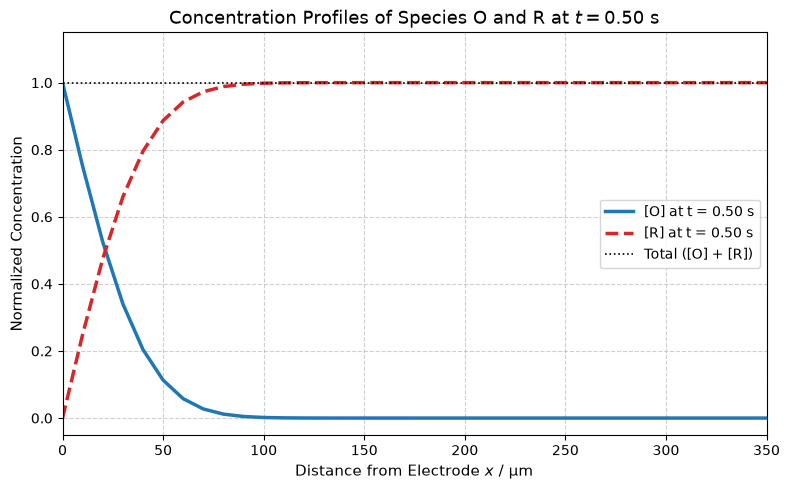

In [9]:
import matplotlib.pyplot as plt

# 1. Target specific time point t = 0.5 s
t_target = 0.5
idx = int(np.argmin(np.abs(result.t - t_target)))
t_actual = result.t[idx]

c_O_specific = c_O[idx, :]
c_R_specific = c_R[idx, :]

# 2. Plot spatial profiles at t = 0.5 s
plt.figure(figsize=(8, 5))
plt.plot(result.x * 1e4, c_O_specific, label=f"[O] at t = {t_actual:.2f} s", color="#1f77b4", lw=2.5)
plt.plot(result.x * 1e4, c_R_specific, label=f"[R] at t = {t_actual:.2f} s", color="#d62728", lw=2.5, linestyle="--")
plt.plot(result.x * 1e4, c_O_specific + c_R_specific, label="Total ([O] + [R])", color="black", lw=1.2, linestyle=":")

plt.title(f"Concentration Profiles of Species O and R at $t = {t_actual:.2f}$ s", fontsize=13)
plt.xlabel("Distance from Electrode $x$ / µm", fontsize=11)
plt.ylabel("Normalized Concentration", fontsize=11)
plt.xlim(0, 350)  # Focus on the active diffusion penetration layer
plt.ylim(-0.05, 1.15)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=10, loc="center right")
plt.tight_layout()
plt.show()

Notice that $[O](x) + [R](x) = 1.0$ everywhere across the domain, illustrating exact mass conservation between the two diffusing species with identical diffusion coefficients.

We can also inspect how both boundary layers expand as time progresses across multiple snapshots:

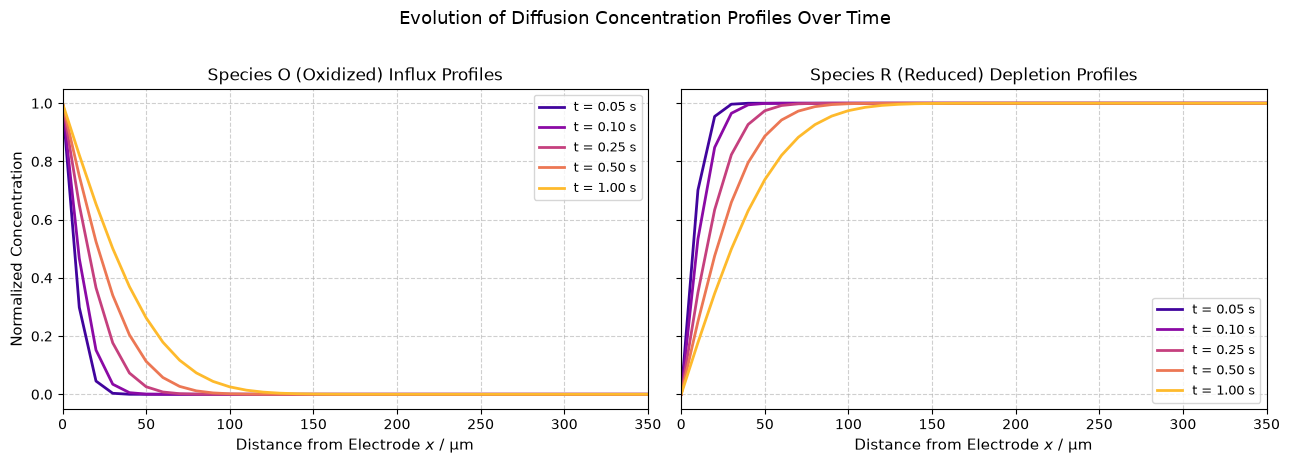

In [10]:
# Multi-timestamp snapshot visualization
times_to_plot = [0.05, 0.1, 0.25, 0.5, 1.0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
colors = plt.cm.plasma(np.linspace(0.1, 0.85, len(times_to_plot)))

for t_val, col in zip(times_to_plot, colors):
    t_idx = int(np.argmin(np.abs(result.t - t_val)))
    t_snap = result.t[t_idx]
    ax1.plot(result.x * 1e4, c_O[t_idx, :], color=col, lw=2, label=f"t = {t_snap:.2f} s")
    ax2.plot(result.x * 1e4, c_R[t_idx, :], color=col, lw=2, label=f"t = {t_snap:.2f} s")

ax1.set_title("Species O (Oxidized) Influx Profiles", fontsize=12)
ax1.set_xlabel("Distance from Electrode $x$ / µm", fontsize=11)
ax1.set_ylabel("Normalized Concentration", fontsize=11)
ax1.set_xlim(0, 350)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(loc="upper right", fontsize=9)

ax2.set_title("Species R (Reduced) Depletion Profiles", fontsize=12)
ax2.set_xlabel("Distance from Electrode $x$ / µm", fontsize=11)
ax2.set_xlim(0, 350)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(loc="lower right", fontsize=9)

plt.suptitle("Evolution of Diffusion Concentration Profiles Over Time", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

---

## 9. Extracting and Plotting Faradaic Currents with `SolverResult`

In the minimal code snippet, Faradaic currents were extracted from the `SolverResult` object:

```python
current_O = result.currents["O"]
current_R = result.currents["R"]
```

### The Physics Behind Current Calculation
During post-processing, Soft Potato automatically evaluates:
1. **Interfacial Molar Flux ($J$):** Evaluated from the concentration gradient at the active electrode ($x = 0$):
   $$J_i(t) = -D_i \left.\frac{\partial c_i}{\partial x}\right\vert_{x=0}$$
   Stored in `result.fluxes[species]`.
2. **Faradaic Current ($I$):** Evaluated by integrating normal flux over the active electrode geometric area $A$:
   $$I_i(t) = n F A J_i(t)$$
   Stored in `result.currents[species]`.

Let's extract the exact numerical values at our specific time ($t^* = 0.5\text{ s}$) and visualize the transient current decay $I(t)$ over time:

=== Extracted Values at t = 0.50 s ===
Surface Flux J_O:       +2.618048e-03 mol/(cm²·s)
Surface Flux J_R:       -2.618048e-03 mol/(cm²·s)
Faradaic Current I_O:   +252.6032 A
Faradaic Current I_R:   -252.6032 A
Net Current (I_O + I_R): 0.000000e+00 A (Mass & charge conserved)


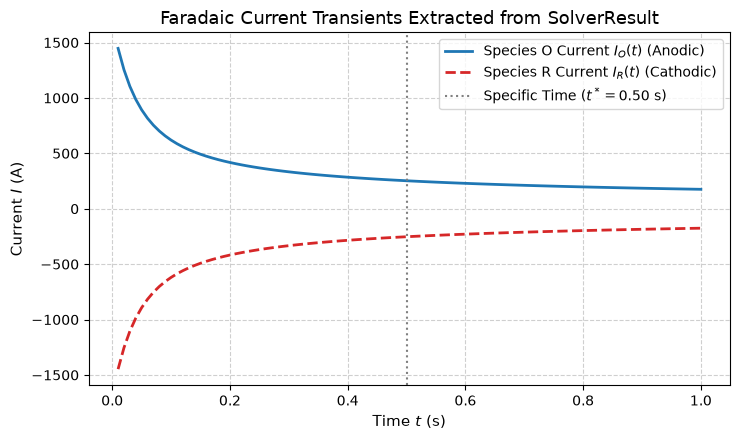

In [11]:
# 1. Inspect extracted values at target time t = 0.5 s
current_O_target = current_O[idx]
current_R_target = current_R[idx]
flux_O_target = result.fluxes["O"][idx]
flux_R_target = result.fluxes["R"][idx]

print(f"=== Extracted Values at t = {t_actual:.2f} s ===")
print(f"Surface Flux J_O:       {flux_O_target:+.6e} mol/(cm²·s)")
print(f"Surface Flux J_R:       {flux_R_target:+.6e} mol/(cm²·s)")
print(f"Faradaic Current I_O:   {current_O_target:+.4f} A")
print(f"Faradaic Current I_R:   {current_R_target:+.4f} A")
print(f"Net Current (I_O + I_R): {current_O_target + current_R_target:.6e} A (Mass & charge conserved)")

# 2. Plot Faradaic current transients vs time
plt.figure(figsize=(7.5, 4.5))
# Exclude the very first point (t=0) to avoid the initial step singularity
t_trans = result.t[1:]
i_O_trans = current_O[1:]
i_R_trans = current_R[1:]

plt.plot(t_trans, i_O_trans, label="Species O Current $I_O(t)$ (Anodic)", color="#1f77b4", lw=2)
plt.plot(t_trans, i_R_trans, label="Species R Current $I_R(t)$ (Cathodic)", color="#d62728", lw=2, linestyle="--")
plt.axvline(t_actual, color="gray", linestyle=":", label=f"Specific Time ($t^* = {t_actual:.2f}$ s)")

plt.title("Faradaic Current Transients Extracted from SolverResult", fontsize=13)
plt.xlabel("Time $t$ (s)", fontsize=11)
plt.ylabel("Current $I$ (A)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

---

## 10. Summary: Standard Workflow with `softpotato.solver`

To simulate any 1D diffusion or reaction-diffusion system in Soft Potato:

1. **Discretize Space:** Build a coordinate grid with `np.linspace()` or utilize non-uniform stretching grids from `softpotato.grid` (`Uniform1DMesh`, `GeometricExpandingMesh`, `ExponentialMesh`).
2. **Define Boundary Conditions:** Use `DirichletBC` for clamped concentration values (potentiostatic control) or `NeumannBC` for fixed fluxes (galvanostatic control or impermeable walls).
3. **Formulate the Problem:** Package the grid, species diffusivities, boundary conditions, and initial profiles into `DiffusionProblem()`.
4. **Select a Solver:** Call `get_solver("explicit")` for explicit FTCS, or select `'crank_nicolson'`, `'implicit'`, or `'scipy_ivp'` based on the stability requirements of your simulation.
5. **Analyze the Results:** Inspect concentrations (`result[species]`), boundary fluxes (`result.fluxes[species]`), and Faradaic currents (`result.currents[species]`) directly from `SolverResult`.

For more details on solver options and mathematical formulations, visit the [softpotato.solver API Reference](../../../api/solver/).